# CCARP — Credit Card Approval Risk & Profit Scoring

**Objective:** End-to-end reproducible walkthrough of temporal-leakage-free credit default scoring (`MONTHS_BALANCE <= T_obs` vs `> T_obs`), duplicate-profile `StratifiedGroupKFold` validation, fold-internal OOF probability calibration (Platt & Isotonic), and unit-economics Expected Profit threshold optimization (`tau*`).

In [1]:
import json
from pathlib import Path
import sys

from IPython.display import Image, display
import pandas as pd

PROJECT_ROOT = Path("..").resolve()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.core.config import PipelineConfig
from src.core.contracts import ModelRunSpec
from src.evaluation.ablation_auditor import evaluate_ablation_regime
from src.evaluation.profit_optimizer import compute_theoretical_cutoff, optimize_profit_threshold
from src.features.behavioral_aggregator import aggregate_behavioral_history, assemble_feature_dataset, build_demographic_only_dataset
from src.features.demographic_cleaner import clean_demographic_records
from src.features.profile_grouping import build_demographic_group_keys, summarize_profile_duplication
from src.features.temporal_splitter import compute_cutoff_retention_grid, is_valid_temporal_partition, partition_temporal_windows
from src.ingestion.kaggle_loader import load_raw_tables
from src.ingestion.relational_join import join_application_credit
from src.modeling.credit_models import train_oof_model
from src.modeling.cv_splitter import create_stratified_group_splits, create_stratified_splits, has_disjoint_groups
from src.modeling.probability_calibrator import fit_and_apply_oof_calibrators

config = PipelineConfig.create_default(PROJECT_ROOT)
print(f"Configured CCARP root: {config.root_dir}")

Configured CCARP root: C:\Users\elmas\Desktop\Projets\DataScience\CCARP


## 1. Data Ingestion, Sentinel Profiling & Relational Join Audit

In [2]:
app_raw, credit_raw = load_raw_tables(config.dataset)
joined = join_application_credit(app_raw, credit_raw)

print("Relational Join Audit:", joined.audit)
n_sentinel = int((joined.application_df["DAYS_EMPLOYED"] == 365243).sum())
n_occ_nan = int(joined.application_df["OCCUPATION_TYPE"].isna().sum())
print(f"DAYS_EMPLOYED == 365243 sentinel rows: {n_sentinel:,} ({100 * n_sentinel / len(joined.application_df):.2f}%)")
print(f"OCCUPATION_TYPE missing rows: {n_occ_nan:,} ({100 * n_occ_nan / len(joined.application_df):.2f}%)")

Relational Join Audit: JoinAuditStats(app_raw_rows=438557, app_unique_ids=438510, app_duplicate_ids=94, credit_raw_rows=1048575, credit_unique_ids=45985, joined_ids=36457, joined_credit_rows=777715, app_only_ids=402053, credit_only_ids=9528)
DAYS_EMPLOYED == 365243 sentinel rows: 6,135 (16.83%)
OCCUPATION_TYPE missing rows: 11,323 (31.06%)


## 2. Strict Causal Temporal Window Partitioning & Cutoff Sensitivity Grid

In [3]:
partition = partition_temporal_windows(joined.credit_df, config.temporal)
assert is_valid_temporal_partition(partition.obs_df, partition.perf_df, config.temporal.t_obs)

print(f"Selected cutoff T_obs={partition.t_obs} | Cohort N={len(partition.cohort_ids):,} | Forward 60+ DPD Positives={int(partition.target_series.sum())} ({100 * float(partition.target_series.mean()):.3f}%)")
print(f"Max obs month: {int(partition.obs_df['MONTHS_BALANCE'].max())} | Min perf month: {int(partition.perf_df['MONTHS_BALANCE'].min())}")

cutoff_grid_df = pd.DataFrame(compute_cutoff_retention_grid(joined, config.temporal))
display(cutoff_grid_df)

Selected cutoff T_obs=-12 | Cohort N=17,220 | Forward 60+ DPD Positives=156 (0.906%)
Max obs month: -12 | Min perf month: -11


,t_obs,perf_horizon_months,cohort_n,retention_pct,positives,default_rate_pct,obs_prior_bad_count,n_demo_groups
0,-24,24,12731,34.92,171,1.343,277,5626
1,-18,18,15053,41.29,160,1.063,348,6276
2,-12,12,17220,47.23,156,0.906,402,6943
3,-6,6,19339,53.05,143,0.739,459,7617


## 3. Duplicate Demographic Profile Clustering & Leakage Ablation

In [4]:
app_keys = joined.application_df.copy()
app_keys["demo_group_key"] = build_demographic_group_keys(app_keys)
cleaned_app = clean_demographic_records(app_keys)

demo_ds = build_demographic_only_dataset(cleaned_app, partition)
obs_beh = aggregate_behavioral_history(partition.obs_df, partition.t_obs)
leak_free_ds = assemble_feature_dataset(cleaned_app, obs_beh, partition)

dup_summary = summarize_profile_duplication(pd.Series(leak_free_ds.group_keys), pd.Series(leak_free_ds.target))
print("Demographic Profile Duplication Audit:", dup_summary)

naive_slice = joined.credit_df[joined.credit_df["ID"].isin(partition.cohort_ids)].copy()
naive_beh = aggregate_behavioral_history(naive_slice, reference_month=0)
naive_ds = assemble_feature_dataset(cleaned_app, naive_beh, partition)

sgkf_full = create_stratified_group_splits(leak_free_ds, config.modeling)
skf_full = create_stratified_splits(leak_free_ds, config.modeling)
assert has_disjoint_groups(sgkf_full, leak_free_ds.group_keys)

spec_lgb = ModelRunSpec("lightgbm", config.modeling, leak_free_ds.schema)
p_skf = train_oof_model(leak_free_ds, skf_full, spec_lgb)
p_sgkf = train_oof_model(leak_free_ds, sgkf_full, spec_lgb)
p_naive = train_oof_model(naive_ds, sgkf_full, spec_lgb)

ablation_df = pd.DataFrame([
    {"Regime": "Leak-Free + StratifiedKFold", **vars(evaluate_ablation_regime(("a", "b", "c"), leak_free_ds.target, p_skf).metrics)},
    {"Regime": "Leak-Free + StratifiedGroupKFold", **vars(evaluate_ablation_regime(("a", "b", "c"), leak_free_ds.target, p_sgkf).metrics)},
    {"Regime": "Naive Full-History + StratifiedGroupKFold", **vars(evaluate_ablation_regime(("a", "b", "c"), naive_ds.target, p_naive).metrics)},
])
display(ablation_df)

Demographic Profile Duplication Audit: {'n_clients': 17220, 'n_unique_groups': 6943, 'n_singleton_groups': 3039, 'n_multi_id_groups': 3904, 'n_clients_in_multi_id_groups': 14181, 'pct_clients_in_multi_id_groups': 82.35, 'max_cluster_size': 19, 'n_positive_multi_id_groups': 81, 'mean_within_positive_cluster_default_rate': 0.3831}


,Regime,roc_auc,pr_auc,brier_score,log_loss_val,ece_10bin,ks_statistic
0,Leak-Free + StratifiedKFold,0.928447,0.470919,0.006095,0.029078,0.000978,0.697420
1,Leak-Free + StratifiedGroupKFold,0.926653,0.408096,0.006479,0.030946,0.001587,0.678392
2,Naive Full-History + StratifiedGroupKFold,0.998828,0.897569,0.002475,0.008262,0.001280,0.985092


## 4. Calibrated LightGBM Verification, Expected Profit Policy & Visual Artifacts

Analytical Break-Even tau_theory = 0.1071
LightGBM Platt Optimal Point: ProfitPoint(threshold=0.076, approval_rate=0.985017, n_approved=16962, approved_bad_rate=0.004304, expected_profit_per_applicant=170.1812, total_portfolio_profit=2930520.0)
Approve-All Baseline: ProfitPoint(threshold=1.0, approval_rate=1.0, n_approved=17220, approved_bad_rate=0.009059, expected_profit_per_applicant=164.7805, total_portfolio_profit=2837520.0)

All Calibrated Models (from artifacts/results.json):


,model_name,calibration,roc_auc,pr_auc,brier_score,log_loss_val,ece_10bin,ks_statistic
0,logistic_regression,raw,0.920327,0.378310,0.006601,0.031710,0.001236,0.679722
1,logistic_regression,platt,0.919762,0.379604,0.006639,0.031699,0.001386,0.675245
2,logistic_regression,isotonic,0.913019,0.371599,0.006616,0.033017,0.000597,0.666090
3,lightgbm,raw,0.926653,0.408096,0.006479,0.030946,0.001587,0.678392
4,lightgbm,platt,0.926155,0.405384,0.006509,0.030904,0.000495,0.678000
5,lightgbm,isotonic,0.919460,0.401087,0.006511,0.032402,0.000876,0.664183
6,xgboost,raw,0.927462,0.410319,0.006593,0.030886,0.000642,0.681601
7,xgboost,platt,0.927140,0.406746,0.006601,0.030906,0.000720,0.678770
8,xgboost,isotonic,0.922406,0.376279,0.006720,0.034844,0.001066,0.680871
9,catboost,raw,0.929850,0.440680,0.006309,0.029892,0.001382,0.676255



Unit-Economics Sensitivity Grid (margin_good x LGD):


,margin_good,lgd,tau_theory,tau_optimal,approval_rate_optimal,expected_profit_optimal,profit_lift_vs_approve_all
0,120.0,0.60,0.090909,0.062,0.984262,112.8223,4.7805
1,120.0,0.70,0.078947,0.062,0.984262,112.0209,5.7909
2,120.0,0.75,0.074074,0.062,0.984262,111.6202,6.2962
3,120.0,0.85,0.065934,0.062,0.984262,110.8188,7.3066
4,150.0,0.60,0.111111,0.070,0.985482,142.2561,4.4861
5,150.0,0.70,0.096774,0.070,0.985482,141.4315,5.4733
6,150.0,0.75,0.090909,0.062,0.984262,141.0279,5.9756
7,150.0,0.85,0.081081,0.062,0.984262,140.2265,6.9861
8,180.0,0.60,0.130435,0.070,0.985482,171.6969,4.1986
9,180.0,0.70,0.113924,0.070,0.985482,170.8722,5.1858



Figure: ccarp_temporal_window_leakage.png


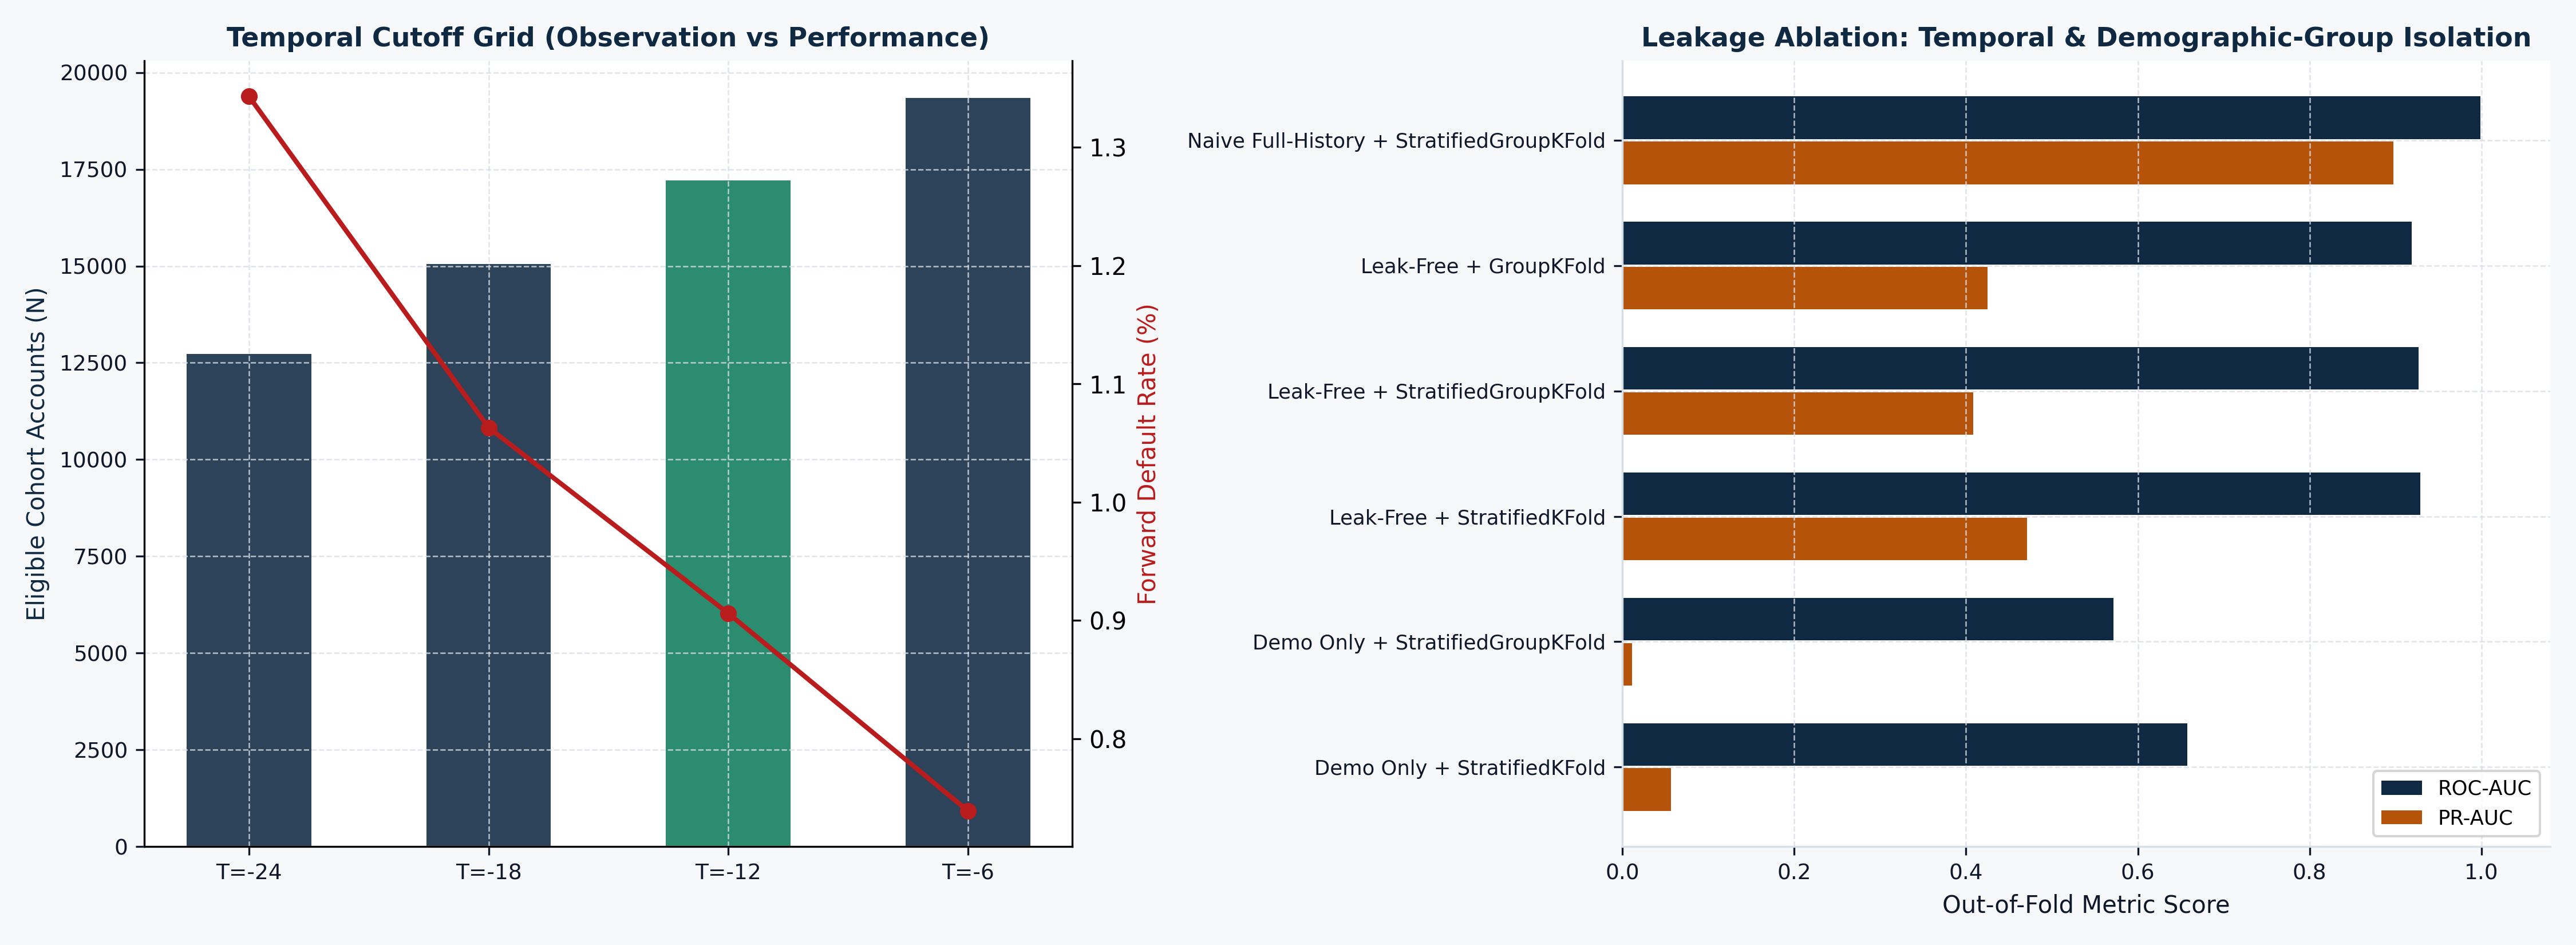


Figure: ccarp_roc_pr_calibration.png


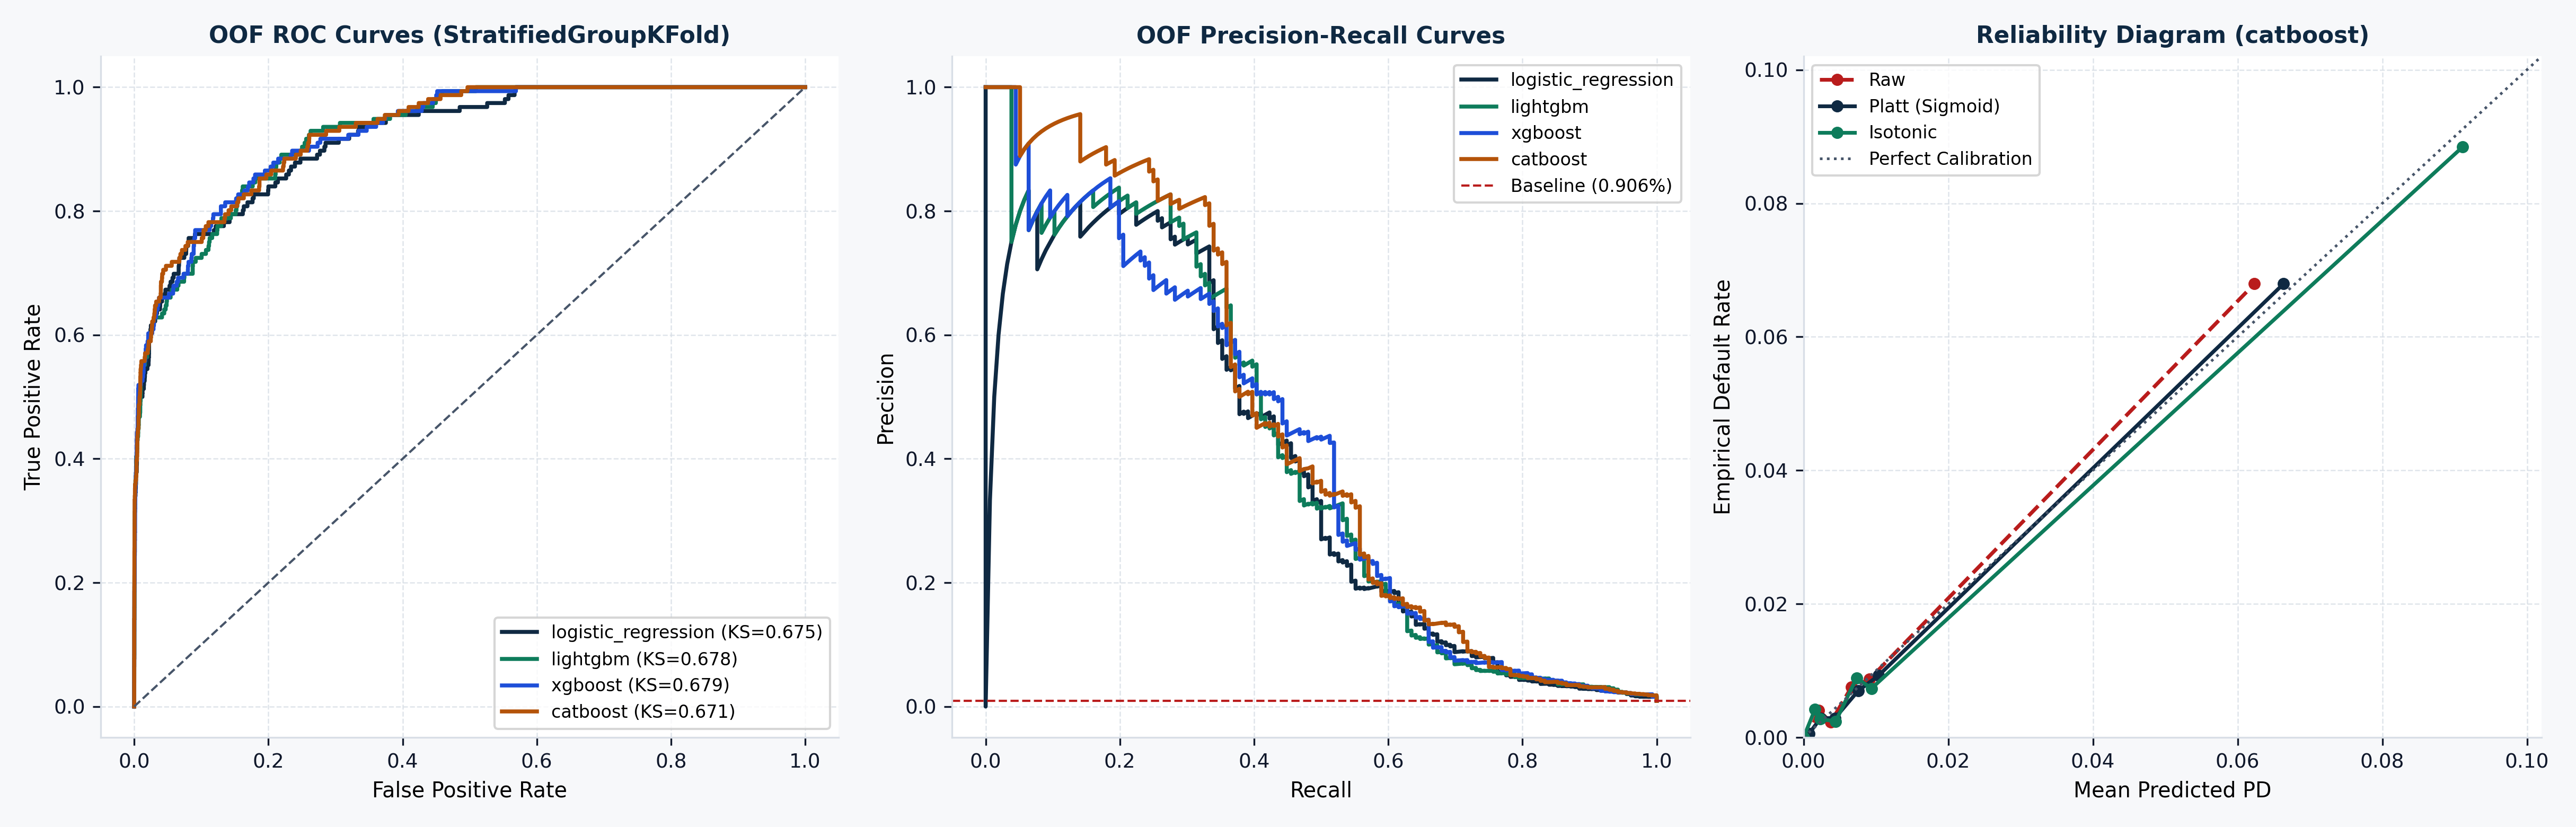


Figure: ccarp_expected_profit_curve.png


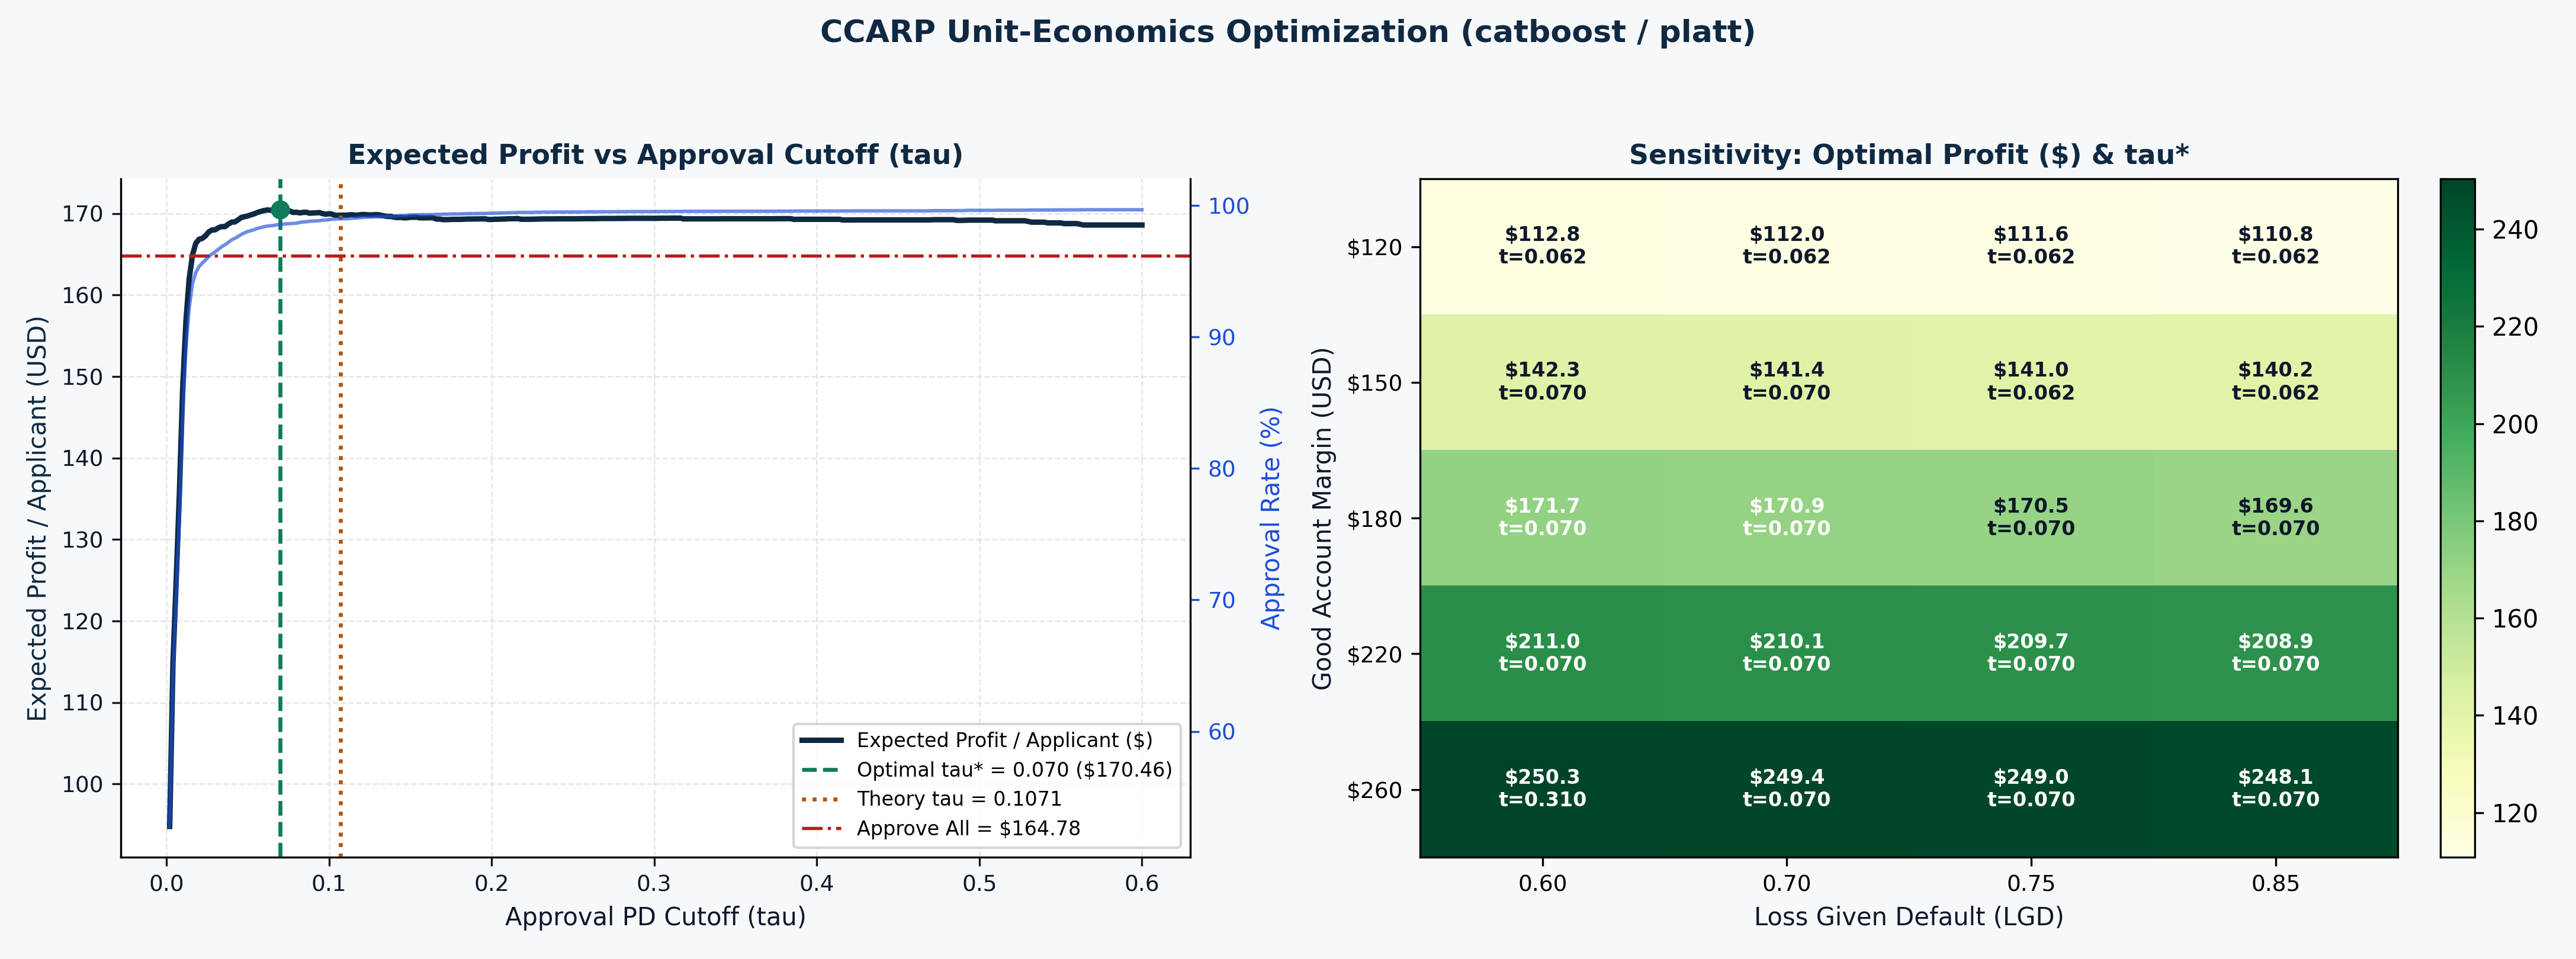


Figure: ccarp_feature_risk_drivers.png


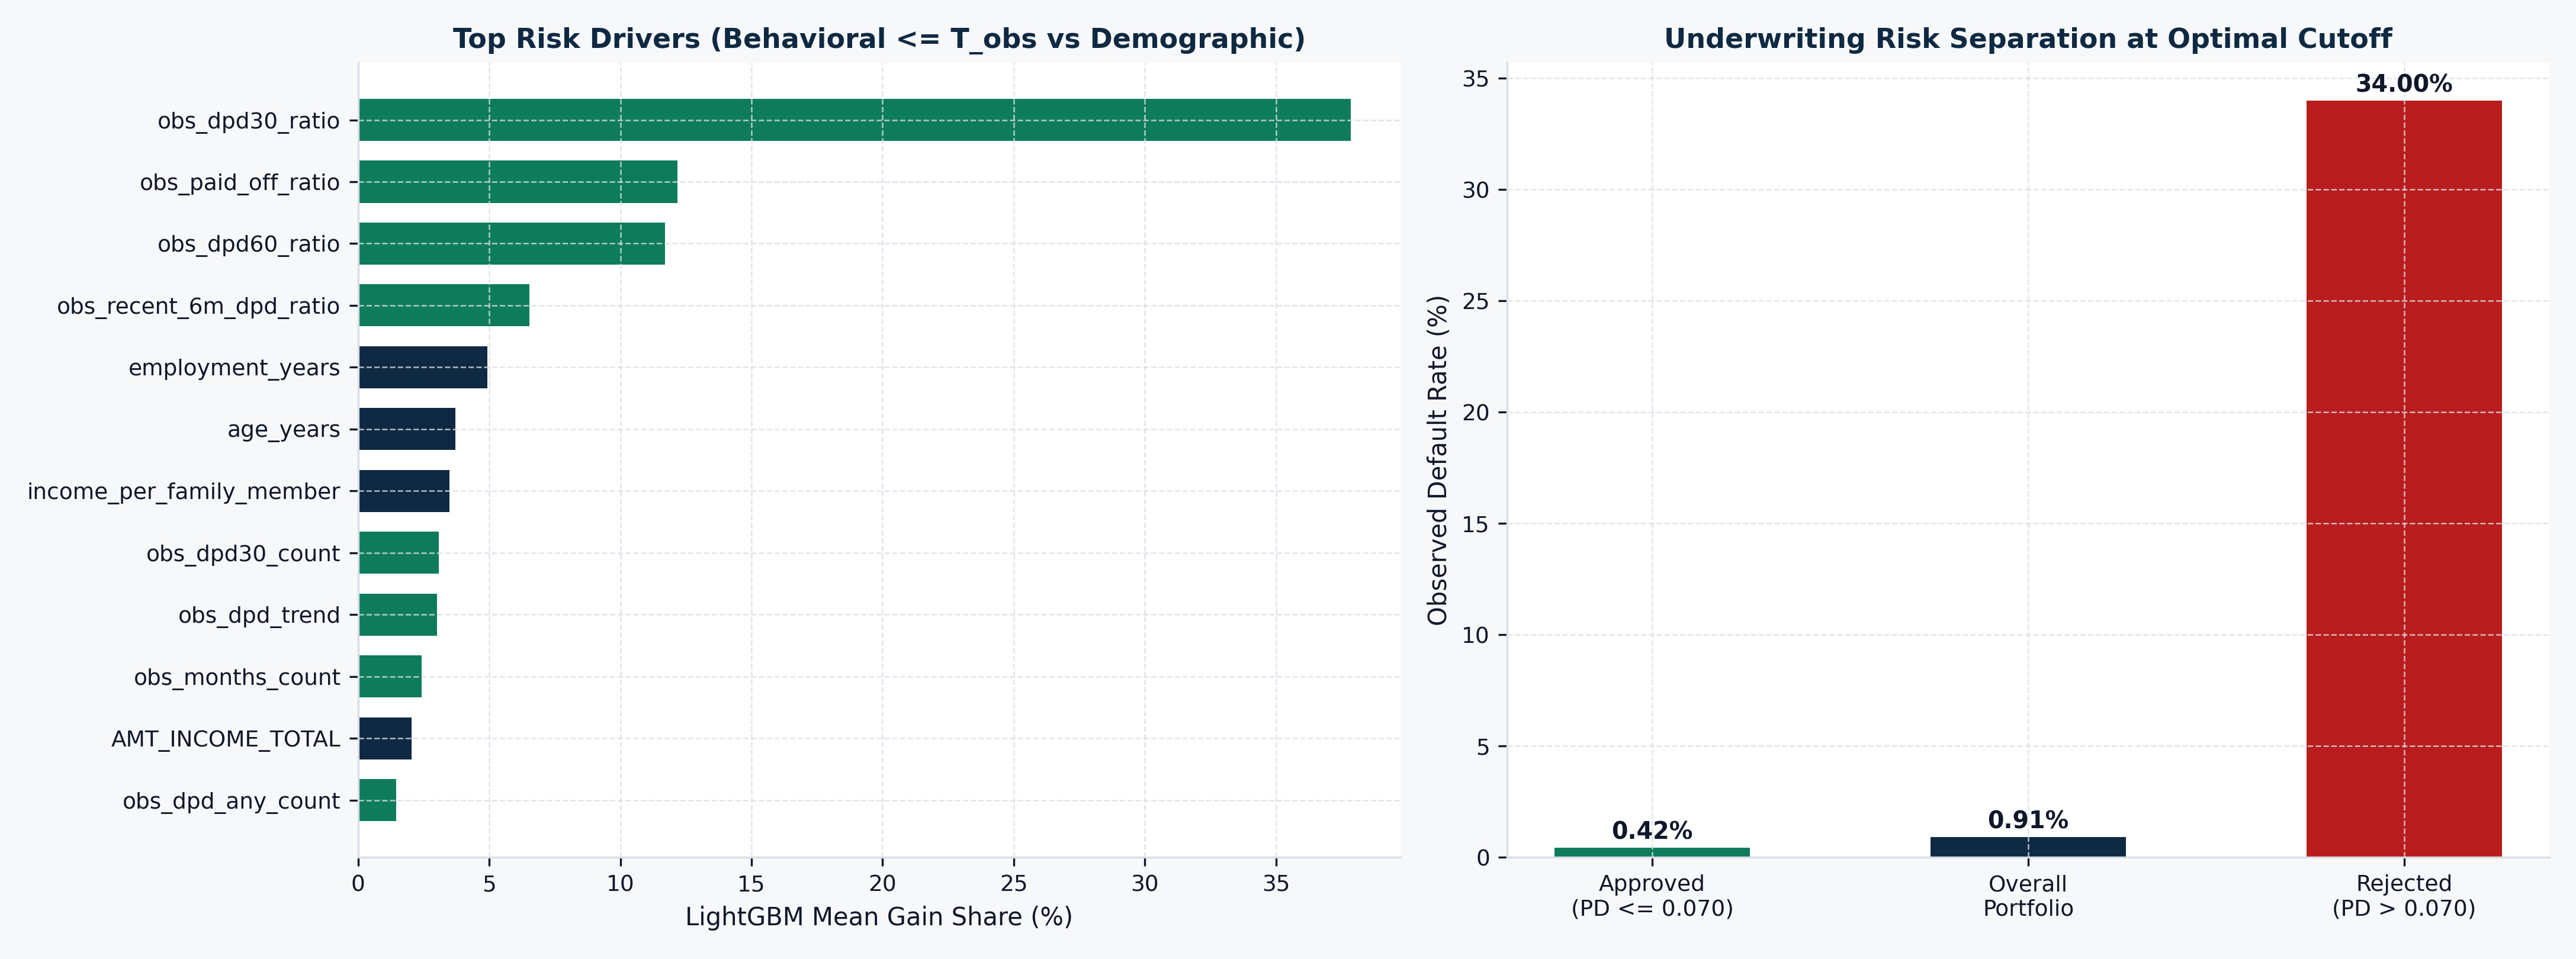

In [5]:
lgb_bundle = fit_and_apply_oof_calibrators(leak_free_ds, sgkf_full, spec_lgb)
profit_lgb = optimize_profit_threshold(lgb_bundle, config.economics, variant="platt")
print(f"Analytical Break-Even tau_theory = {compute_theoretical_cutoff(config.economics):.4f}")
print(f"LightGBM Platt Optimal Point: {profit_lgb.optimal_point}")
print(f"Approve-All Baseline: {profit_lgb.approve_all_point}")

results = json.loads(config.plots.results_json_path.read_text(encoding="utf-8"))
print("\nAll Calibrated Models (from artifacts/results.json):")
display(pd.DataFrame(results["model_metrics"]))

print("\nUnit-Economics Sensitivity Grid (margin_good x LGD):")
display(pd.DataFrame(results["profit_optimization"]["sensitivity_grid"]))

for fig_name in results["figure_filenames"]:
    print(f"\nFigure: {fig_name}")
    display(Image(filename=str(config.plots.images_dir / fig_name)))